# Element multiomics: single-cell RNA to imaging-morphology matching calibration
**The goal: connecting RNA and imaging morphology.** The Element Biosciences screen (258,896 A549 cells, each with cell-painting + 4 protein stains + guide + 3' transcriptome, row-aligned) is the one dataset with **true per-cell imaging+RNA pairs**, so it is ground truth for calibrating how well that connection works before a larger pooled screen.

We predict each cell's RNA (50 PCs of HVG-normalized counts) from its imaging features, held-out (5-fold, per-fold scaling, RidgeCV), and measure held-out R² and cross-modal retrieval (rank the true partner by cosine of predicted-vs-actual). Four axes, each with a shuffled-pair null (spec co-designed with collaborators):
1. **Pooling** k = 1 to 400 cells averaged within condition blocks.
2. **Feature panel**: full embedding vs cell-paint stains vs a ~26-feature interpretable panel (shape + per-channel intensities + nuclear DNA).
3. **Extent**: whole-cell vs nuclear-region features (the `_Nuclear` suffix), the analogue of a perinuclear crop.
4. **Link strength**: degrade imaging with noise, plot accuracy vs achieved imaging-to-RNA R².

Full reproducer: `element_calibration.py` (downloads Element from Tim's CDN, writes `results/element_matching_calibration.csv`). This notebook reads that table.

**Headline:** per-cell RNA-to-morphology is weak but real (R² about 0.04, retrieval about 25x chance); **whole-cell features carry ~2.3x the RNA signal of nuclear-region features** (perinuclear crops cost more than half); an interpretable 26-feature panel recovers about half the full-embedding R²; and pooling helps only modestly here because this screen has 28 perturbations. The strong cross-modal regime (R² 0.45 to 0.50) lives at the perturbation/gene level with many perturbations, as in the Altair analyses.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi":110,"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
df=pd.read_csv("results/element_matching_calibration.csv")
df

,axis,k,n_groups,r2,top10,med_pct,null_top10,which,n_feat,noise
0,cells_per_group,1.0,8000.0,0.041494,0.021375,0.074250,0.001125,NaN,NaN,NaN
1,cells_per_group,10.0,799.0,0.050374,0.083855,0.131414,0.018773,NaN,NaN,NaN
2,cells_per_group,50.0,159.0,0.055718,0.088050,0.245283,0.037736,NaN,NaN,NaN
3,cells_per_group,100.0,79.0,0.051858,0.151899,0.316456,0.101266,NaN,NaN,NaN
4,cells_per_group,200.0,39.0,0.039629,0.179487,0.384615,0.256410,NaN,NaN,NaN
5,cells_per_group,400.0,19.0,0.008805,1.000000,0.421053,0.789474,NaN,NaN,NaN
6,panel,NaN,NaN,0.041367,0.021625,NaN,0.001250,full,797.0,NaN
7,panel,NaN,NaN,0.029813,0.013750,NaN,0.001250,cell_paint_stains,388.0,NaN
8,panel,NaN,NaN,0.021016,0.006250,NaN,0.001250,interpretable_panel,26.0,NaN
9,extent,NaN,NaN,0.040966,0.021500,NaN,NaN,whole_cell,773.0,NaN


## Pooling: held-out R² vs cells per group
R² is the clean readout here. Retrieval at high k is confounded by the shrinking gallery (few groups), so observed tracks the null; we show R². Pooling lifts R² from about 0.04 (single cell) to about 0.056 around k=50, then falls at k=200/400 because only 39 and 19 groups remain to fit the model. This screen's 28 perturbations cannot reach the Altair gene-level regime.

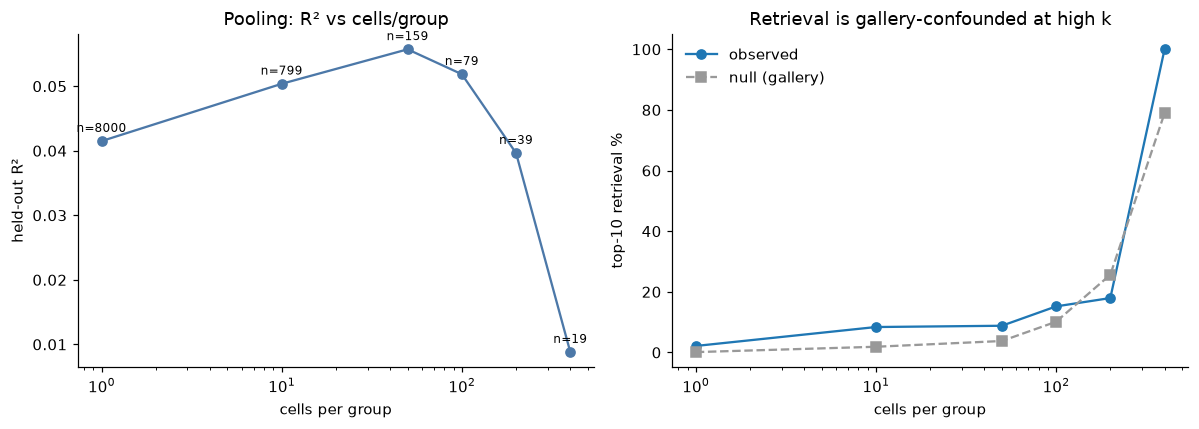

In [2]:
a=df[df.axis=="cells_per_group"]
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(a.k,a.r2,"o-",color="#4C78A8"); ax[0].set_xscale("log"); ax[0].set_xlabel("cells per group"); ax[0].set_ylabel("held-out R²"); ax[0].set_title("Pooling: R² vs cells/group")
for x,y,ng in zip(a.k,a.r2,a.n_groups): ax[0].annotate(f"n={int(ng)}",(x,y),textcoords="offset points",xytext=(0,6),fontsize=8,ha="center")
ax[1].plot(a.k,a.top10*100,"o-",label="observed"); ax[1].plot(a.k,a.null_top10*100,"s--",color="0.6",label="null (gallery)")
ax[1].set_xscale("log"); ax[1].set_xlabel("cells per group"); ax[1].set_ylabel("top-10 retrieval %"); ax[1].set_title("Retrieval is gallery-confounded at high k"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig("figures/element/pooling_r2.png",bbox_inches="tight",dpi=150); plt.show()

## Feature panel and extent
**Panel:** the full embedding (R² 0.041) beats cell-paint stains (0.030) and a 26-feature interpretable panel (0.021). A small biology-anchored panel captures about half the RNA link; the full/learned set is about 2x better.
**Extent:** whole-cell features (0.041) carry about 2.3x the RNA-predictive signal of nuclear-region features (0.018). This directly quantifies the cost of a perinuclear restriction, the general concern with perinuclear crops.

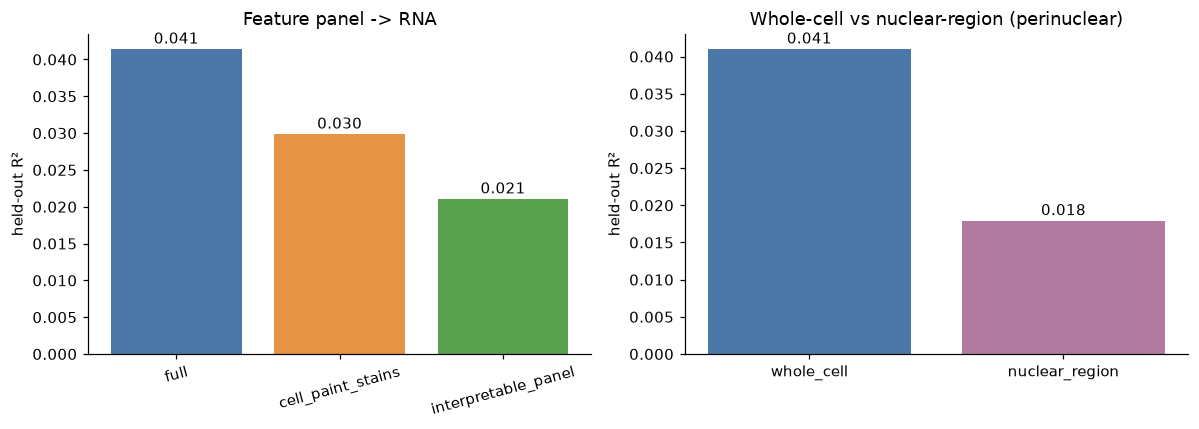

In [3]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
p=df[df.axis=="panel"]; ax[0].bar(p.which,p.r2,color=["#4C78A8","#E49444","#59A14F"])
for i,(w,r) in enumerate(zip(p.which,p.r2)): ax[0].text(i,r+.0008,f"{r:.3f}",ha="center")
ax[0].set_ylabel("held-out R²"); ax[0].set_title("Feature panel -> RNA"); ax[0].tick_params(axis="x",rotation=15)
e=df[df.axis=="extent"]; ax[1].bar(e.which,e.r2,color=["#4C78A8","#B07AA1"])
for i,(w,r) in enumerate(zip(e.which,e.r2)): ax[1].text(i,r+.0008,f"{r:.3f}",ha="center")
ax[1].set_ylabel("held-out R²"); ax[1].set_title("Whole-cell vs nuclear-region (perinuclear)")
plt.tight_layout(); plt.savefig("figures/element/panel_extent.png",bbox_inches="tight",dpi=150); plt.show()

## Link strength: matching degrades smoothly
Adding noise to the imaging features drops both R² and retrieval monotonically, giving a clean calibration of how matching accuracy scales with the imaging-to-RNA link strength.

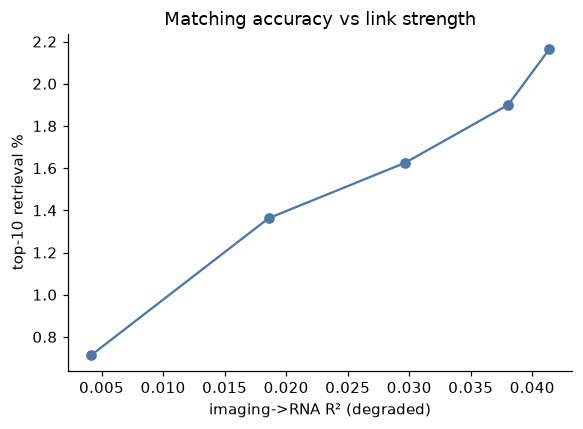

In [4]:
l=df[df.axis=="link_strength"].sort_values("r2")
fig,ax=plt.subplots(figsize=(5.4,4)); ax.plot(l.r2,l.top10*100,"o-",color="#4C78A8")
ax.set_xlabel("imaging->RNA R² (degraded)"); ax.set_ylabel("top-10 retrieval %"); ax.set_title("Matching accuracy vs link strength")
plt.tight_layout(); plt.savefig("figures/element/link_strength.png",bbox_inches="tight",dpi=150); plt.show()

## Takeaways
- **Connect RNA and morphology at the aggregate (guide/gene) level, not per single cell.** Per-cell matching is real but weak (R² about 0.04); the strong regime (R² 0.45 to 0.50) needs many perturbations aggregated. For a pooled screen, plan readouts at the guide/gene level.
- **Use whole-cell features, not perinuclear.** Nuclear-region features carry less than half the RNA signal of whole-cell. Crops or territories that miss the cell periphery will under-connect morphology to RNA, especially where the signal is peripheral.
- **A learned/full feature set beats a small panel**, but a ~26-feature biology panel (shape, per-channel intensity, DNA) still carries about half the signal, so interpretable readouts are usable.
- **Matching accuracy scales smoothly with link strength**, so link-feature quality is the lever.
- Method guardrails applied throughout: raw/degraded baselines, shuffled-pair nulls, pooling within condition blocks (never within donor, which is circular).

**Caveats:** 28 perturbations and one cell line (A549); per-cell RNA is sparse so 50 PCs of HVGs; linear predictors (a floor); high-k pooling points (k>=200) have too few groups to fit and are shown only for completeness.